In [1]:
import sys

print("Python is working!")
print("Python version:", sys.version)

Python is working!
Python version: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]


In [4]:
%pip install pandas numpy scikit-learn xgboost matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import sklearn
import xgboost
import matplotlib
import seaborn
import joblib

print("All libraries imported successfully!")
print("XGBoost version:", xgboost.__version__)

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!
XGBoost version: 3.4.1


In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv("../data/DataCoSupplyChainDataset.csv", encoding="latin1")

# Display the first five rows
df.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/DataCoSupplyChainDataset.csv'

In [4]:
import pandas as pd

df = pd.read_csv(
    "data/DataCoSupplyChainDataset.csv",
    encoding="latin1"
)

df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [5]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (180519, 53)

Column names:
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price',

In [6]:
# Display delivery-related columns
print("Delivery Status values:")
print(df["Delivery Status"].value_counts(dropna=False))

print("\nLate delivery risk values:")
print(df["Late_delivery_risk"].value_counts(dropna=False))

print("\nShipping modes:")
print(df["Shipping Mode"].value_counts(dropna=False))

print("\nMissing values in important columns:")
print(
    df[
        [
            "Delivery Status",
            "Late_delivery_risk",
            "Days for shipping (real)",
            "Days for shipment (scheduled)",
            "Shipping Mode"
        ]
    ].isnull().sum()
)

Delivery Status values:
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

Late delivery risk values:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Shipping modes:
Shipping Mode
Standard Class    107752
Second Class       35216
First Class        27814
Same Day            9737
Name: count, dtype: int64

Missing values in important columns:
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
Shipping Mode                    0
dtype: int64


In [7]:
# Compare delivery status with the existing delay-risk label
pd.crosstab(
    df["Delivery Status"],
    df["Late_delivery_risk"],
    margins=True
)

Late_delivery_risk,0,1,All
Delivery Status,,,
Advance shipping,41592,0,41592
Late delivery,0,98977,98977
Shipping canceled,7754,0,7754
Shipping on time,32196,0,32196
All,81542,98977,180519


In [8]:
# Check whether actual and scheduled shipping duration agree
df[
    [
        "Delivery Status",
        "Late_delivery_risk",
        "Days for shipping (real)",
        "Days for shipment (scheduled)"
    ]
].sample(10, random_state=42)

,Delivery Status,Late_delivery_risk,Days for shipping (real),Days for shipment (scheduled)
80120,Late delivery,1,5,4
19670,Late delivery,1,2,1
114887,Advance shipping,0,2,4
120110,Late delivery,1,5,4
56658,Advance shipping,0,2,4
99465,Late delivery,1,5,4
40749,Late delivery,1,6,4
22688,Advance shipping,0,2,4
154389,Late delivery,1,6,4
47301,Shipping on time,0,4,4


In [9]:
# Inspect the data types of potentially useful columns
columns_to_check = [
    "Type",
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Category Name",
    "Customer Segment",
    "Order Region",
    "Order State",
    "Order Status",
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount Rate",
    "Order Profit Per Order",
    "Order Item Total",
    "Order Date (DateOrders)",
    "Shipping Mode",
    "Late_delivery_risk"
]

df[columns_to_check].info()

KeyError: "['Order Date (DateOrders)'] not in index"

In [10]:
columns_to_check = [
    "Type",
    "Days for shipment (scheduled)",
    "Benefit per order",
    "Sales per customer",
    "Category Name",
    "Customer Segment",
    "Order Region",
    "Order State",
    "Order Status",
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount Rate",
    "Order Profit Per Order",
    "Order Item Total",
    "order date (DateOrders)",
    "Shipping Mode",
    "Late_delivery_risk"
]

df[columns_to_check].info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 17 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipment (scheduled)  180519 non-null  int64  
 2   Benefit per order              180519 non-null  float64
 3   Sales per customer             180519 non-null  float64
 4   Category Name                  180519 non-null  str    
 5   Customer Segment               180519 non-null  str    
 6   Order Region                   180519 non-null  str    
 7   Order State                    180519 non-null  str    
 8   Order Status                   180519 non-null  str    
 9   Order Item Quantity            180519 non-null  int64  
 10  Order Item Product Price       180519 non-null  float64
 11  Order Item Discount Rate       180519 non-null  float64
 12  Order Profit Per Order         180519 non

In [11]:
df[columns_to_check].head(10)

,Type,Days for shipment (scheduled),Benefit per order,Sales per customer,Category Name,Customer Segment,Order Region,Order State,Order Status,Order Item Quantity,Order Item Product Price,Order Item Discount Rate,Order Profit Per Order,Order Item Total,order date (DateOrders),Shipping Mode,Late_delivery_risk
0,DEBIT,4,91.250000,314.640015,Sporting Goods,Consumer,Southeast Asia,Java Occidental,COMPLETE,1,327.75,0.04,91.250000,314.640015,1/31/2018 22:56,Standard Class,0
1,TRANSFER,4,-249.089996,311.359985,Sporting Goods,Consumer,South Asia,Rajastán,PENDING,1,327.75,0.05,-249.089996,311.359985,1/13/2018 12:27,Standard Class,1
2,CASH,4,-247.779999,309.720001,Sporting Goods,Consumer,South Asia,Rajastán,CLOSED,1,327.75,0.06,-247.779999,309.720001,1/13/2018 12:06,Standard Class,0
3,DEBIT,4,22.860001,304.809998,Sporting Goods,Home Office,Oceania,Queensland,COMPLETE,1,327.75,0.07,22.860001,304.809998,1/13/2018 11:45,Standard Class,0
4,PAYMENT,4,134.210007,298.250000,Sporting Goods,Corporate,Oceania,Queensland,PENDING_PAYMENT,1,327.75,0.09,134.210007,298.250000,1/13/2018 11:24,Standard Class,0
5,TRANSFER,4,18.580000,294.980011,Sporting Goods,Consumer,Oceania,Queensland,CANCELED,1,327.75,0.10,18.580000,294.980011,1/13/2018 11:03,Standard Class,0
6,DEBIT,1,95.180000,288.420013,Sporting Goods,Home Office,Eastern Asia,Guangdong,COMPLETE,1,327.75,0.12,95.180000,288.420013,1/13/2018 10:42,First Class,1
7,TRANSFER,1,68.430000,285.140015,Sporting Goods,Corporate,Eastern Asia,Guangdong,PROCESSING,1,327.75,0.13,68.430000,285.140015,1/13/2018 10:21,First Class,1
8,CASH,2,133.720001,278.589996,Sporting Goods,Corporate,Eastern Asia,Guangdong,CLOSED,1,327.75,0.15,133.720001,278.589996,1/13/2018 10:00,Second Class,1
9,CASH,1,132.149994,275.309998,Sporting Goods,Corporate,Eastern Asia,Guangdong,CLOSED,1,327.75,0.16,132.149994,275.309998,1/13/2018 9:39,First Class,1


In [12]:
# Define the initial input features
feature_columns = [
    "Type",
    "Days for shipment (scheduled)",
    "Category Name",
    "Customer Segment",
    "Order Region",
    "Order State",
    "Order Item Quantity",
    "Order Item Product Price",
    "Order Item Discount Rate",
    "Shipping Mode"
]

target_column = "Late_delivery_risk"

# Create the feature matrix and target
X = df[feature_columns].copy()
y = df[target_column].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nInput features:")
print(X.head())

Features shape: (180519, 10)
Target shape: (180519,)

Target distribution:
Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Input features:
       Type  Days for shipment (scheduled)   Category Name Customer Segment  \
0     DEBIT                              4  Sporting Goods         Consumer   
1  TRANSFER                              4  Sporting Goods         Consumer   
2      CASH                              4  Sporting Goods         Consumer   
3     DEBIT                              4  Sporting Goods      Home Office   
4   PAYMENT                              4  Sporting Goods        Corporate   

     Order Region      Order State  Order Item Quantity  \
0  Southeast Asia  Java Occidental                    1   
1      South Asia         Rajastán                    1   
2      South Asia         Rajastán                    1   
3         Oceania       Queensland                    1   
4         Oceania       Queensland                    1   

   Order It

In [13]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (144415, 10)
Testing features: (36104, 10)

Training target distribution:
Late_delivery_risk
1    79181
0    65234
Name: count, dtype: int64

Testing target distribution:
Late_delivery_risk
1    19796
0    16308
Name: count, dtype: int64


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# Identify categorical and numerical columns
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

# Convert categorical values into numerical features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numerical", "passthrough", numerical_features)
    ]
)

# Create the complete ML pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=200,
                max_depth=5,
                learning_rate=0.1,
                random_state=42,
                eval_metric="logloss",
                n_jobs=-1
            )
        )
    ]
)

print("\nPipeline created successfully!")

Categorical features: ['Type', 'Category Name', 'Customer Segment', 'Order Region', 'Order State', 'Shipping Mode']
Numerical features: ['Days for shipment (scheduled)', 'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount Rate']

Pipeline created successfully!


C:\Users\KIIT0001\AppData\Local\Temp\ipykernel_25432\104317464.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from pandas.api.types import is_string_dtype

# Identify categorical and numerical columns
categorical_features = [
    col for col in X_train.columns
    if is_string_dtype(X_train[col].dtype)
]

numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numerical", "passthrough", numerical_features)
    ]
)

# XGBoost pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=200,
                max_depth=5,
                learning_rate=0.1,
                random_state=42,
                eval_metric="logloss",
                n_jobs=-1
            )
        )
    ]
)

print("Pipeline created successfully!")

Categorical features: ['Type', 'Category Name', 'Customer Segment', 'Order Region', 'Order State', 'Shipping Mode']
Numerical features: ['Days for shipment (scheduled)', 'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount Rate']
Pipeline created successfully!


In [16]:
print("Training started...")

model.fit(X_train, y_train)

print("Training completed successfully!")

Training started...
Training completed successfully!


MODEL EVALUATION
----------------------------------------
Accuracy: 0.7008
Precision: 0.8483
Recall: 0.5532
F1-score: 0.6697

Detailed classification report:
              precision    recall  f1-score   support

           0       0.62      0.88      0.73     16308
           1       0.85      0.55      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.72      0.70     36104
weighted avg       0.74      0.70      0.70     36104



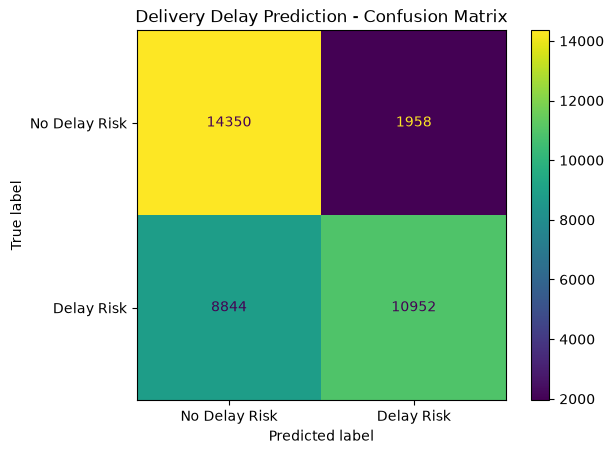

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate predictions on unseen test records
y_pred = model.predict(X_test)

# Calculate evaluation metrics
print("MODEL EVALUATION")
print("-" * 40)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Delay Risk", "Delay Risk"]
)

display.plot()
plt.title("Delivery Delay Prediction - Confusion Matrix")
plt.show()

In [18]:

# Check feature importance from the trained XGBoost model

preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
importances = classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print("Top 15 Important Features:")
display(importance_df.head(15))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("Top 15 Features for Delivery Delay Prediction")
plt.tight_layout()
plt.show()

Top 15 Important Features:


TypeError: 'ConfusionMatrixDisplay' object is not callable

Top 15 Important Features:


,Feature,Importance
1170,numerical__Days for shipment (scheduled),0.405431
1166,categorical__Shipping Mode_First Class,0.077221
3,categorical__Type_TRANSFER,0.018823
1168,categorical__Shipping Mode_Second Class,0.009515
384,categorical__Order State_Duarte,0.004557
724,categorical__Order State_Massachusetts,0.004265
957,categorical__Order State_San Juan,0.004242
1167,categorical__Shipping Mode_Same Day,0.004184
162,categorical__Order State_Atlántida,0.003992
644,categorical__Order State_Lacio,0.003810


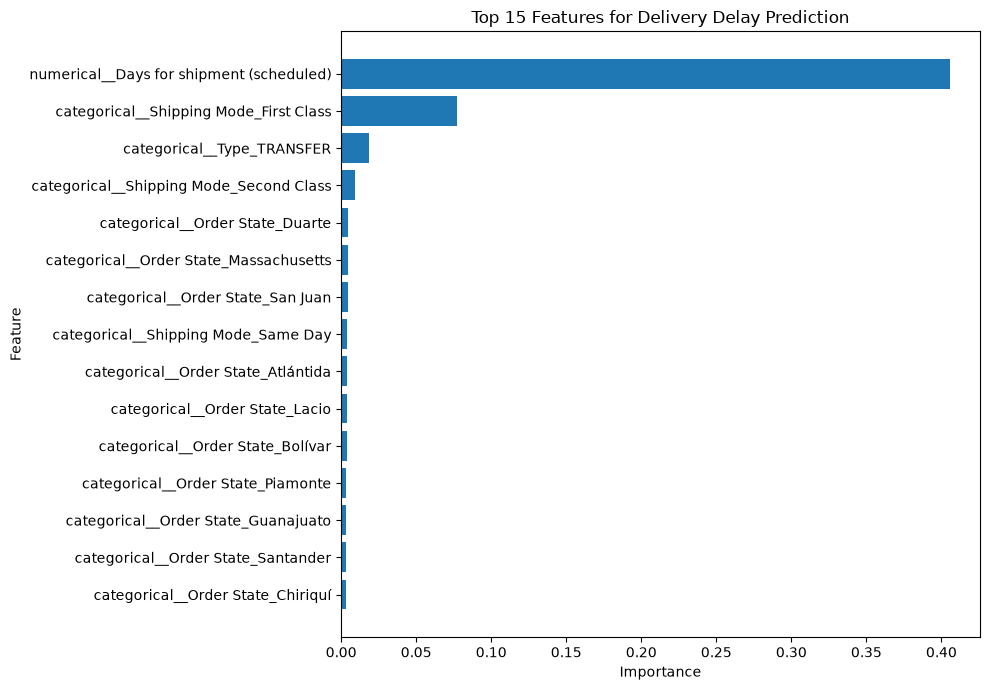

In [19]:

from IPython.display import display as show_table

# Get feature importance from your trained model
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
importances = classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print("Top 15 Important Features:")
show_table(importance_df.head(15))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features for Delivery Delay Prediction")
plt.tight_layout()
plt.show()


In [20]:

# Inspect the features used by the model
print("Input features used by the model:")
print(X.columns.tolist())

print("\nTarget column:")
print(target_column if "target_column" in globals() else y.name)

# Check for columns that could reveal the final delivery outcome
possible_leakage_columns = [
    col for col in X.columns
    if any(word in col.lower() for word in [
        "real", "actual", "delivery status",
        "late_delivery_risk", "shipping date"
    ])
]

print("\nColumns to review for possible data leakage:")
print(possible_leakage_columns)


Input features used by the model:
['Type', 'Days for shipment (scheduled)', 'Category Name', 'Customer Segment', 'Order Region', 'Order State', 'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount Rate', 'Shipping Mode']

Target column:
Late_delivery_risk

Columns to review for possible data leakage:
[]


In [21]:

# Check how the target relates to delivery status
print("Delivery status vs late delivery risk:")
display(pd.crosstab(
    df["Delivery Status"],
    df["Late_delivery_risk"],
    margins=True
))

# Check scheduled vs actual shipping duration
print("\nScheduled and actual shipping duration:")
display(df[
    ["Days for shipment (scheduled)",
     "Days for shipping (real)"]
].describe())

# Check the relationship between actual and scheduled duration
print("\nFirst 10 rows:")
display(df[
    ["Delivery Status",
     "Late_delivery_risk",
     "Days for shipment (scheduled)",
     "Days for shipping (real)"]
].head(10))


Delivery status vs late delivery risk:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [22]:

from IPython.display import display as show_table
import pandas as pd

# Check delivery status vs late delivery risk
print("Delivery status vs late delivery risk:")
show_table(pd.crosstab(
    df["Delivery Status"],
    df["Late_delivery_risk"],
    margins=True
))

# Check scheduled vs actual shipping duration
print("\nScheduled and actual shipping duration:")
show_table(df[
    ["Days for shipment (scheduled)",
     "Days for shipping (real)"]
].describe())

# Show the first 10 rows
print("\nFirst 10 rows:")
show_table(df[
    ["Delivery Status",
     "Late_delivery_risk",
     "Days for shipment (scheduled)",
     "Days for shipping (real)"]
].head(10))


Delivery status vs late delivery risk:


Late_delivery_risk,0,1,All
Delivery Status,,,
Advance shipping,41592,0,41592
Late delivery,0,98977,98977
Shipping canceled,7754,0,7754
Shipping on time,32196,0,32196
All,81542,98977,180519



Scheduled and actual shipping duration:


,Days for shipment (scheduled),Days for shipping (real)
count,180519.000000,180519.000000
mean,2.931847,3.497654
std,1.374449,1.623722
min,0.000000,0.000000
25%,2.000000,2.000000
50%,4.000000,3.000000
75%,4.000000,5.000000
max,4.000000,6.000000



First 10 rows:


,Delivery Status,Late_delivery_risk,Days for shipment (scheduled),Days for shipping (real)
0,Advance shipping,0,4,3
1,Late delivery,1,4,5
2,Shipping on time,0,4,4
3,Advance shipping,0,4,3
4,Advance shipping,0,4,2
5,Shipping canceled,0,4,6
6,Late delivery,1,1,2
7,Late delivery,1,1,2
8,Late delivery,1,2,3
9,Late delivery,1,1,2


In [23]:

# Check whether the target matches actual delivery outcomes

print("Delivery status counts:")
print(df["Delivery Status"].value_counts())

print("\nLate delivery risk by actual shipping duration:")
print(pd.crosstab(
    df["Days for shipping (real)"] >
    df["Days for shipment (scheduled)"],
    df["Late_delivery_risk"],
    margins=True
))

print("\nCheck target consistency:")
print(pd.crosstab(
    df["Delivery Status"],
    df["Late_delivery_risk"],
    normalize="index"
).round(3))


Delivery status counts:
Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

Late delivery risk by actual shipping duration:
Late_delivery_risk      0      1     All
row_0                                   
False               77119      0   77119
True                 4423  98977  103400
All                 81542  98977  180519

Check target consistency:
Late_delivery_risk    0    1
Delivery Status             
Advance shipping    1.0  0.0
Late delivery       0.0  1.0
Shipping canceled   1.0  0.0
Shipping on time    1.0  0.0


In [24]:

print("Features used by the model:")
print(list(X.columns))

print("\nTarget column:")
print(y.name)

print("\nCheck for leakage columns:")
leakage_columns = [
    col for col in X.columns
    if col in [
        "Delivery Status",
        "Days for shipping (real)",
        "Late_delivery_risk"
    ]
]
print(leakage_columns)


Features used by the model:
['Type', 'Days for shipment (scheduled)', 'Category Name', 'Customer Segment', 'Order Region', 'Order State', 'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount Rate', 'Shipping Mode']

Target column:
Late_delivery_risk

Check for leakage columns:
[]


In [25]:

# Check the current model and preprocessing pipeline

print("Available model-related variables:")

for name in [
    "pipeline",
    "model",
    "best_model",
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "y_pred"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

print("\nTraining and testing sizes:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


Available model-related variables:
model: Pipeline
X_train: DataFrame
X_test: DataFrame
y_train: Series
y_test: Series
y_pred: ndarray

Training and testing sizes:
X_train: (144415, 10)
X_test: (36104, 10)
y_train: (144415,)
y_test: (36104,)


In [26]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Get prediction probabilities from the existing model
y_proba = model.predict_proba(X_test)[:, 1]

# Compare different thresholds
results = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    y_threshold_pred = (y_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_threshold_pred),
        "Precision": precision_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_threshold_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_threshold_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)
print("Model performance at different thresholds:")
display(results_df.round(4))

Model performance at different thresholds:


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [27]:

from IPython.display import display as show_table

print("Model performance at different thresholds:")
show_table(results_df.round(4))


Model performance at different thresholds:


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.30,0.5562,0.5529,0.9963,0.7111
1,0.35,0.6030,0.5883,0.9186,0.7173
2,0.40,0.6791,0.7221,0.6741,0.6973
3,0.45,0.7009,0.8143,0.5888,0.6834
4,0.50,0.7008,0.8483,0.5532,0.6697
5,0.55,0.6992,0.8507,0.5475,0.6663
6,0.60,0.6990,0.8527,0.5452,0.6651


In [28]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

best_threshold = 0.35

y_prob = model.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob >= best_threshold).astype(int)

print("FINAL MODEL PERFORMANCE")
print("-----------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_final), 4))
print("Precision:", round(precision_score(y_test, y_pred_final), 4))
print("Recall:", round(recall_score(y_test, y_pred_final), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_final), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))


FINAL MODEL PERFORMANCE
-----------------------
Accuracy: 0.603
Precision: 0.5883
Recall: 0.9186
F1 Score: 0.7173

Confusion Matrix:
[[ 3584 12724]
 [ 1611 18185]]


In [29]:

import joblib

# Save the trained model
joblib.dump(model, "delivery_delay_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [31]:

import pandas as pd

def predict_delivery_delay(
    order_type,
    scheduled_days,
    category,
    customer_segment,
    region,
    state,
    quantity,
    product_price,
    discount_rate,
    shipping_mode
):
    new_order = pd.DataFrame([{
        "Type": order_type,
        "Days for shipment (scheduled)": scheduled_days,
        "Category Name": category,
        "Customer Segment": customer_segment,
        "Order Region": region,
        "Order State": state,
        "Order Item Quantity": quantity,
        "Order Item Product Price": product_price,
        "Order Item Discount Rate": discount_rate,
        "Shipping Mode": shipping_mode
    }])

    probability = model.predict_proba(new_order)[0][1]
    threshold = 0.35

    prediction = (
        "Delay Risk" if probability >= threshold
        else "No Delay Risk"
    )

    print("Prediction:", prediction)
    print("Delay Risk Probability:", round(probability * 100, 2), "%")

    return prediction


In [32]:
print("Model exists:", "model" in globals())
print("Prediction function exists:", "predict_delivery_delay" in globals())

if "model" in globals():
    print("Model type:", type(model))

Model exists: True
Prediction function exists: True
Model type: <class 'sklearn.pipeline.Pipeline'>


In [33]:

print(predict_delivery_delay)

print("\nModel input features:")
print(model.feature_names_in_ if hasattr(model, "feature_names_in_") else "Features are stored inside the pipeline")


<function predict_delivery_delay at 0x0000017A4B328720>

Model input features:
['Type' 'Days for shipment (scheduled)' 'Category Name' 'Customer Segment'
 'Order Region' 'Order State' 'Order Item Quantity'
 'Order Item Product Price' 'Order Item Discount Rate' 'Shipping Mode']


In [34]:

predict_delivery_delay(
    order_type="DEBIT",
    scheduled_days=4,
    category="Sporting Goods",
    customer_segment="Consumer",
    region="South Asia",
    state="Rajasthan",
    quantity=1,
    product_price=327.75,
    discount_rate=0.05,
    shipping_mode="Standard Class"
)


Prediction: Delay Risk
Delay Risk Probability: 39.57 %


'Delay Risk'

In [35]:
print("Model type:", type(model))
print("Model classes:", model.classes_ if hasattr(model, "classes_") else "Check pipeline")
print("Features expected:", list(X.columns))
print("Target classes:", y.value_counts().to_dict())

Model type: <class 'sklearn.pipeline.Pipeline'>
Model classes: [0 1]
Features expected: ['Type', 'Days for shipment (scheduled)', 'Category Name', 'Customer Segment', 'Order Region', 'Order State', 'Order Item Quantity', 'Order Item Product Price', 'Order Item Discount Rate', 'Shipping Mode']
Target classes: {1: 98977, 0: 81542}


In [36]:
import inspect

print(inspect.getsource(predict_delivery_delay))

def predict_delivery_delay(
    order_type,
    scheduled_days,
    category,
    customer_segment,
    region,
    state,
    quantity,
    product_price,
    discount_rate,
    shipping_mode
):
    new_order = pd.DataFrame([{
        "Type": order_type,
        "Days for shipment (scheduled)": scheduled_days,
        "Category Name": category,
        "Customer Segment": customer_segment,
        "Order Region": region,
        "Order State": state,
        "Order Item Quantity": quantity,
        "Order Item Product Price": product_price,
        "Order Item Discount Rate": discount_rate,
        "Shipping Mode": shipping_mode
    }])

    probability = model.predict_proba(new_order)[0][1]
    threshold = 0.35

    prediction = (
        "Delay Risk" if probability >= threshold
        else "No Delay Risk"
    )

    print("Prediction:", prediction)
    print("Delay Risk Probability:", round(probability * 100, 2), "%")

    return prediction



In [37]:
test_order = pd.DataFrame([{
    "Type": "DEBIT",
    "Days for shipment (scheduled)": 4,
    "Category Name": "Sporting Goods",
    "Customer Segment": "Consumer",
    "Order Region": "South Asia",
    "Order State": "Rajasthan",
    "Order Item Quantity": 1,
    "Order Item Product Price": 327.75,
    "Order Item Discount Rate": 0.05,
    "Shipping Mode": "Standard Class"
}])

print("Model classes:", model.classes_)
print("Class probabilities:", model.predict_proba(test_order))
print("Probability for class 1:", model.predict_proba(test_order)[0][1])

Model classes: [0 1]
Class probabilities: [[0.6043078  0.39569226]]
Probability for class 1: 0.39569226


In [38]:
test_cases = [
    {
        "Test": "Test 1 - Standard Class, 4 days",
        "Type": "DEBIT",
        "Days for shipment (scheduled)": 4,
        "Category Name": "Sporting Goods",
        "Customer Segment": "Consumer",
        "Order Region": "South Asia",
        "Order State": "Rajasthan",
        "Order Item Quantity": 1,
        "Order Item Product Price": 327.75,
        "Order Item Discount Rate": 0.05,
        "Shipping Mode": "Standard Class"
    },
    {
        "Test": "Test 2 - First Class",
        "Type": "DEBIT",
        "Days for shipment (scheduled)": 4,
        "Category Name": "Sporting Goods",
        "Customer Segment": "Consumer",
        "Order Region": "South Asia",
        "Order State": "Rajasthan",
        "Order Item Quantity": 1,
        "Order Item Product Price": 327.75,
        "Order Item Discount Rate": 0.05,
        "Shipping Mode": "First Class"
    },
    {
        "Test": "Test 3 - 2 scheduled days",
        "Type": "DEBIT",
        "Days for shipment (scheduled)": 2,
        "Category Name": "Sporting Goods",
        "Customer Segment": "Consumer",
        "Order Region": "South Asia",
        "Order State": "Rajasthan",
        "Order Item Quantity": 1,
        "Order Item Product Price": 327.75,
        "Order Item Discount Rate": 0.05,
        "Shipping Mode": "Standard Class"
    }
]

results = []

for case in test_cases:
    order = pd.DataFrame([{
        key: value
        for key, value in case.items()
        if key != "Test"
    }])

    probability = model.predict_proba(order)[0][1]

    results.append({
        "Test": case["Test"],
        "Delay Risk Probability (%)": round(probability * 100, 2),
        "Prediction": "Delay Risk" if probability >= 0.35
                      else "No Delay Risk"
    })

display(pd.DataFrame(results))

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [39]:
from IPython.display import display as show_table

show_table(pd.DataFrame(results))

,Test,Delay Risk Probability (%),Prediction
0,"Test 1 - Standard Class, 4 days",39.570000,Delay Risk
1,Test 2 - First Class,95.050003,Delay Risk
2,Test 3 - 2 scheduled days,74.169998,Delay Risk


In [40]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities for the test dataset
y_probability = model.predict_proba(X_test)[:, 1]

# Apply the current threshold
threshold = 0.35
y_pred_eval = (y_probability >= threshold).astype(int)

print("MODEL EVALUATION AT THRESHOLD 0.35")
print("----------------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_eval), 4))
print("Precision:", round(precision_score(y_test, y_pred_eval, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_eval, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred_eval, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_eval))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_eval, zero_division=0))

MODEL EVALUATION AT THRESHOLD 0.35
----------------------------------
Accuracy: 0.603
Precision: 0.5883
Recall: 0.9186
F1 Score: 0.7173

Confusion Matrix:
[[ 3584 12724]
 [ 1611 18185]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.22      0.33     16308
           1       0.59      0.92      0.72     19796

    accuracy                           0.60     36104
   macro avg       0.64      0.57      0.53     36104
weighted avg       0.63      0.60      0.54     36104



In [41]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use the probabilities calculated from X_test
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]
threshold_results = []

for threshold in thresholds:
    predictions = (y_probability >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

show_table(pd.DataFrame(threshold_results).round(4))


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.30,0.5562,0.5529,0.9963,0.7111
1,0.35,0.6030,0.5883,0.9186,0.7173
2,0.40,0.6791,0.7221,0.6741,0.6973
3,0.45,0.7009,0.8143,0.5888,0.6834
4,0.50,0.7008,0.8483,0.5532,0.6697
5,0.55,0.6992,0.8507,0.5475,0.6663
6,0.60,0.6990,0.8527,0.5452,0.6651


In [42]:

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

plt.figure(figsize=(9, 5))

for metric in metrics:
    plt.plot(
        threshold_results_df["Threshold"],
        threshold_results_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Model Performance at Different Thresholds")
plt.xticks(thresholds)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


NameError: name 'threshold_results_df' is not defined

<Figure size 900x500 with 0 Axes>

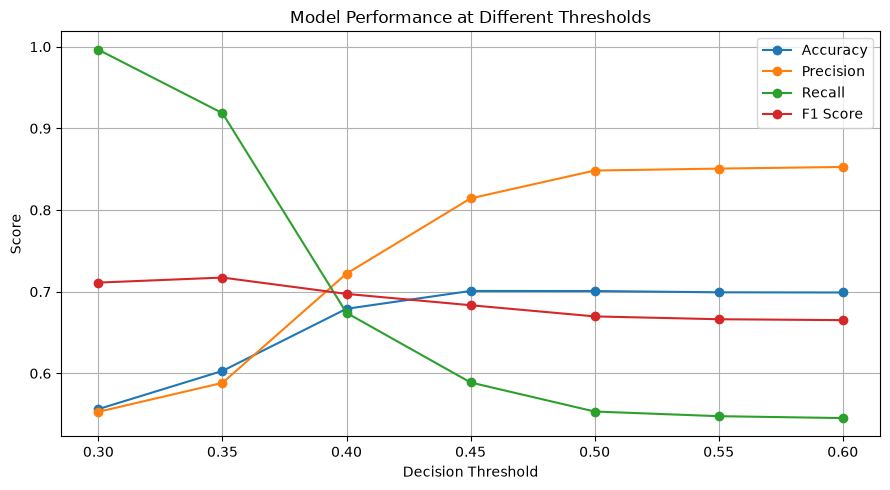

In [43]:

import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

threshold_results_df = pd.DataFrame(threshold_results)

plt.figure(figsize=(9, 5))

for metric in metrics:
    plt.plot(
        threshold_results_df["Threshold"],
        threshold_results_df[metric],
        marker="o",
        label=metric
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Model Performance at Different Thresholds")
plt.xticks(thresholds)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [44]:

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Compare models using the same train-test split
models = {
    "Current Model": model,
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    )
}

comparison_results = []

for name, estimator in models.items():
    candidate = clone(estimator)
    candidate.fit(X_train, y_train)

    y_pred = candidate.predict(X_test)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(4))


ValueError: could not convert string to float: 'PAYMENT'

In [45]:

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

models = {
    "Current Model": model,
    "Logistic Regression": clone(model).set_params(
        classifier=LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    ),
    "Random Forest": clone(model).set_params(
        classifier=RandomForestClassifier(
            n_estimators=100,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
}

comparison_results = []

for name, candidate in models.items():
    candidate.fit(X_train, y_train)
    y_pred = candidate.predict(X_test)

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(4))


C:\Users\KIIT0001\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


KeyboardInterrupt: 

In [ ]:
print(model)
print("\nPipeline parameters:")
print(model.named_steps.keys())

In [46]:
print(model.named_steps.keys())

dict_keys(['preprocessor', 'classifier'])


In [47]:
from sklearn.metrics import accuracy_score, f1_score

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.7008087746510082
F1 Score: 0.6697242096251452


In [48]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rf_model = clone(model)

rf_model.set_params(
    classifier=RandomForestClassifier(
        n_estimators=50,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, rf_pred, zero_division=0), 4))

Random Forest Results
---------------------
Accuracy: 0.6983
Precision: 0.8375
Recall: 0.5581
F1 Score: 0.6699


In [49]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

comparison = []

for name, fitted_model in [
    ("Current Model", model),
    ("Random Forest", rf_model)
]:
    probabilities = fitted_model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.35).astype(int)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [50]:
from IPython.display import display as show_table

show_table(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Current Model,0.603,0.5883,0.9186,0.7173
1,Random Forest,0.552,0.5504,0.9984,0.7097


In [51]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

probabilities = model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in np.arange(0.30, 0.61, 0.05):
    predictions = (probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.round(4).to_string(index=False))

 Threshold  Accuracy  Precision  Recall  F1 Score
      0.30    0.5562     0.5529  0.9963    0.7111
      0.35    0.6030     0.5883  0.9186    0.7173
      0.40    0.6791     0.7221  0.6741    0.6973
      0.45    0.7009     0.8143  0.5888    0.6834
      0.50    0.7008     0.8483  0.5532    0.6697
      0.55    0.6992     0.8507  0.5475    0.6663
      0.60    0.6990     0.8527  0.5452    0.6651


Confusion Matrix:
[[ 3584 12724]
 [ 1611 18185]]


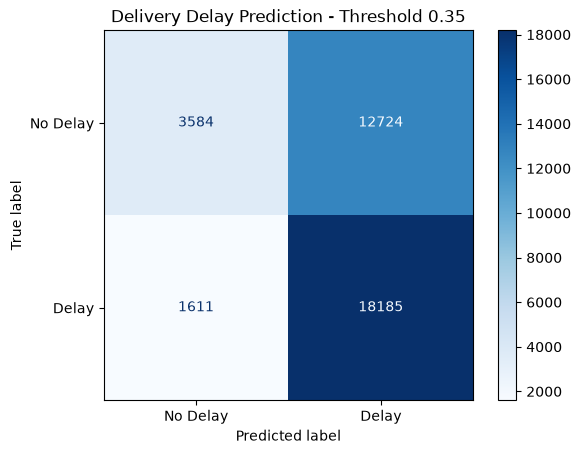

In [52]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

probabilities = model.predict_proba(X_test)[:, 1]
y_pred_035 = (probabilities >= 0.35).astype(int)

cm = confusion_matrix(y_test, y_pred_035)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Delay", "Delay"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Delivery Delay Prediction - Threshold 0.35")
plt.show()

In [53]:
from sklearn.metrics import confusion_matrix
import pandas as pd

probabilities = model.predict_proba(X_test)[:, 1]

threshold_comparison = []

for threshold in [0.35, 0.40, 0.45]:
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    threshold_comparison.append({
        "Threshold": threshold,
        "Correct No-Delay": tn,
        "False Alarms": fp,
        "Missed Delays": fn,
        "Detected Delays": tp
    })

print(pd.DataFrame(threshold_comparison).to_string(index=False))

 Threshold  Correct No-Delay  False Alarms  Missed Delays  Detected Delays
      0.35              3584         12724           1611            18185
      0.40             11173          5135           6452            13344
      0.45             13649          2659           8140            11656


In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

metric_results = []

for threshold in [0.35, 0.40, 0.45]:
    predictions = (probabilities >= threshold).astype(int)

    metric_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

print(pd.DataFrame(metric_results).round(4).to_string(index=False))

 Threshold  Accuracy  Precision  Recall  F1 Score
      0.35    0.6030     0.5883  0.9186    0.7173
      0.40    0.6791     0.7221  0.6741    0.6973
      0.45    0.7009     0.8143  0.5888    0.6834


In [55]:

# STEP 2: Inspect the existing model and dataset

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTarget distribution in training data:")
print(y_train.value_counts(normalize=True).round(4))

print("\nData types of training features:")
print(X_train.dtypes.value_counts())

print("\nCategorical columns:")
print(X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist())

print("\nCurrent model pipeline:")
print(model)

print("\nPreprocessing configuration:")
print(model.named_steps["preprocessor"])

print("\nClassifier:")
print(model.named_steps["classifier"])


Training data shape: (144415, 10)
Testing data shape: (36104, 10)

Target distribution in training data:
Late_delivery_risk
1    0.5483
0    0.4517
Name: proportion, dtype: float64

Data types of training features:
str        6
int64      2
float64    2
Name: count, dtype: int64

Categorical columns:
['Type', 'Category Name', 'Customer Segment', 'Order Region', 'Order State', 'Shipping Mode']

Current model pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type', 'Category Name',
                                                   'Customer Segment',
                                                   'Order Region',
                                                   'Order State',
                                                   'Shipping Mode']),
                                         

In [56]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions using the existing fitted model
xgb_predictions = model.predict(X_test)

print("XGBoost Model Evaluation")
print("------------------------")
print("Accuracy:", round(
    accuracy_score(y_test, xgb_predictions), 4
))
print("Precision:", round(
    precision_score(y_test, xgb_predictions, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, xgb_predictions, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, xgb_predictions, zero_division=0), 4
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test, xgb_predictions, zero_division=0
))


XGBoost Model Evaluation
------------------------
Accuracy: 0.7008
Precision: 0.8483
Recall: 0.5532
F1 Score: 0.6697

Confusion Matrix:
[[14350  1958]
 [ 8844 10952]]

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.88      0.73     16308
           1       0.85      0.55      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.72      0.70     36104
weighted avg       0.74      0.70      0.70     36104



In [57]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

# Get probabilities for the delay class (class 1)
xgb_probabilities = model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.35, 0.40, 0.45, 0.50]:
    predictions = (xgb_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

print(pd.DataFrame(threshold_results).round(4).to_string(index=False))


 Threshold  Accuracy  Precision  Recall  F1 Score
      0.35    0.6030     0.5883  0.9186    0.7173
      0.40    0.6791     0.7221  0.6741    0.6973
      0.45    0.7009     0.8143  0.5888    0.6834
      0.50    0.7008     0.8483  0.5532    0.6697


In [58]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Create a tuned copy of your existing pipeline
tuned_model = clone(model)

tuned_model.set_params(
    classifier__n_estimators=300,
    classifier__max_depth=4,
    classifier__learning_rate=0.05,
    classifier__subsample=0.8,
    classifier__colsample_bytree=0.8
)

# Train the model
tuned_model.fit(X_train, y_train)

# Predict delay probabilities
tuned_probabilities = tuned_model.predict_proba(X_test)[:, 1]

# Evaluate using threshold 0.35
tuned_predictions = (tuned_probabilities >= 0.35).astype(int)

print("Tuned XGBoost Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))
print("Precision:", round(precision_score(y_test, tuned_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, tuned_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, tuned_predictions, zero_division=0), 4))


Tuned XGBoost Results
---------------------
Accuracy: 0.6018
Precision: 0.5875
Recall: 0.9195
F1 Score: 0.7169


In [59]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

comparison = []

for name, fitted_model in [
    ("Original XGBoost", model),
    ("Tuned XGBoost", tuned_model)
]:
    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    for threshold in [0.35, 0.40, 0.45]:
        predictions = (probabilities >= threshold).astype(int)

        comparison.append({
            "Model": name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [60]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

comparison = []

for name, fitted_model in [
    ("Original XGBoost", model),
    ("Tuned XGBoost", tuned_model)
]:
    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    for threshold in [0.35, 0.40, 0.45]:
        predictions = (probabilities >= threshold).astype(int)

        comparison.append({
            "Model": name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [61]:

from IPython.display import display as show_table
import pandas as pd

comparison_df = pd.DataFrame(comparison)

show_table(comparison_df.round(4))


,Model,Threshold,Accuracy,Precision,Recall,F1 Score
0,Original XGBoost,0.35,0.6030,0.5883,0.9186,0.7173
1,Original XGBoost,0.40,0.6791,0.7221,0.6741,0.6973
2,Original XGBoost,0.45,0.7009,0.8143,0.5888,0.6834
3,Tuned XGBoost,0.35,0.6018,0.5875,0.9195,0.7169
4,Tuned XGBoost,0.40,0.6783,0.7173,0.6821,0.6993
5,Tuned XGBoost,0.45,0.6992,0.8126,0.5866,0.6814


Final Confusion Matrix:
[[ 3584 12724]
 [ 1611 18185]]


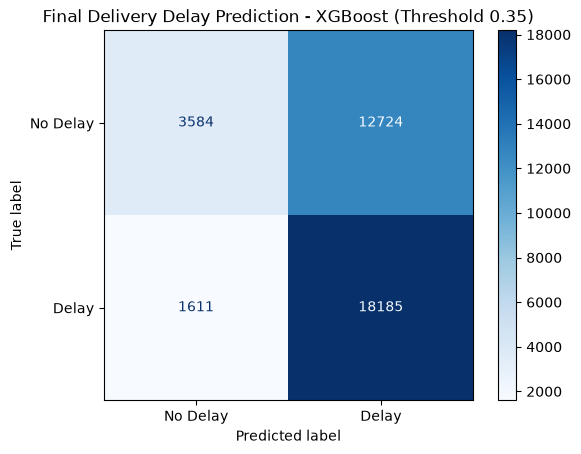

In [62]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Use the original XGBoost model
final_model = model

# Predict probabilities and apply threshold 0.35
final_probabilities = final_model.predict_proba(X_test)[:, 1]
final_predictions = (final_probabilities >= 0.35).astype(int)

# Generate confusion matrix
cm = confusion_matrix(y_test, final_predictions, labels=[0, 1])

print("Final Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Delay", "Delay"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final Delivery Delay Prediction - XGBoost (Threshold 0.35)")
plt.show()


In [63]:

import joblib

# Save the complete trained pipeline
joblib.dump(model, "delivery_delay_model.pkl")

print("Model saved successfully!")
print("File: delivery_delay_model.pkl")


Model saved successfully!
File: delivery_delay_model.pkl


In [64]:

import os

model_path = "delivery_delay_model.pkl"

if os.path.exists(model_path):
    print("Model file exists!")
    print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")
else:
    print("Model file not found.")


Model file exists!
File size: 365.48 KB


In [65]:

import joblib
import numpy as np

# Load the saved model
loaded_model = joblib.load("delivery_delay_model.pkl")

# Generate predictions using the loaded model
loaded_probabilities = loaded_model.predict_proba(X_test)[:, 1]

# Apply your selected threshold
loaded_predictions = (loaded_probabilities >= 0.35).astype(int)

print("Saved model loaded successfully!")
print("Sample predictions:", loaded_predictions[:10])
print("Sample delay probabilities:",
      np.round(loaded_probabilities[:10], 3))


Saved model loaded successfully!
Sample predictions: [1 1 0 1 1 0 1 1 1 1]
Sample delay probabilities: [0.402 0.399 0.345 0.462 0.478 0.344 0.997 0.402 0.997 0.793]


In [66]:
import sys
print(sys.executable)

C:\Users\KIIT0001\anaconda3\python.exe


In [67]:

import numpy as np

# Find an example predicted as No Delay
probabilities = model.predict_proba(X_test)[:, 1]
positions = np.where(probabilities < 0.35)[0]

if len(positions) > 0:
    i = positions[0]
    print("Example order details:")
    print(X_test.iloc[i].to_dict())
    print("\nPredicted delay probability:",
          round(probabilities[i] * 100, 2), "%")
    print("Prediction: NO DELIVERY DELAY")
else:
    print("No matching example found.")


Example order details:
{'Type': 'TRANSFER', 'Days for shipment (scheduled)': 4, 'Category Name': 'Cleats', 'Customer Segment': 'Consumer', 'Order Region': 'Northern Europe', 'Order State': 'Inglaterra', 'Order Item Quantity': 2, 'Order Item Product Price': 59.99000168, 'Order Item Discount Rate': 0.07, 'Shipping Mode': 'Standard Class'}

Predicted delay probability: 34.47 %
Prediction: NO DELIVERY DELAY


In [70]:

import joblib
import pandas as pd

# Load the saved pipeline
delivery_model = joblib.load("delivery_delay_model.pkl")

def predict_delivery_delay(order_details, threshold=0.35):
    order_df = pd.DataFrame([order_details])

    probability = delivery_model.predict_proba(order_df)[0, 1]
    prediction = int(probability >= threshold)

    return {
        "delay_probability": round(float(probability), 4),
        "predicted_status": (
            "Delay" if prediction == 1
            else "No Delivery Delay"
        ),
        "threshold": threshold
    }


In [71]:

sample_order = X_test.iloc[0].to_dict()

result = predict_delivery_delay(sample_order)

print("Prediction Result:")
print("Delay Probability:", result["delay_probability"])
print("Predicted Status:", result["predicted_status"])


Prediction Result:
Delay Probability: 0.4025
Predicted Status: Delay


In [72]:
# Check which features XGBoost considers important

import pandas as pd

importance = model.feature_importances_

feature_names = X_train.columns

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

AttributeError: 'Pipeline' object has no attribute 'feature_importances_'

In [73]:
# Inspect the steps inside the trained pipeline
print(model.named_steps.keys())

dict_keys(['preprocessor', 'classifier'])


In [74]:
xgb_model = model.named_steps["classifier"]

print(type(xgb_model))
print(xgb_model.feature_importances_)

<class 'xgboost.sklearn.XGBClassifier'>
[0.00112487 0.00086605 0.00093487 ... 0.00040321 0.00048416 0.00049457]


In [75]:
# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get importance values from XGBoost
importance = model.named_steps["classifier"].feature_importances_

# Create the feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort from highest to lowest importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.to_string(index=False))

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [76]:
import pandas as pd
from IPython.display import display as show_table

# Get feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Get importance values from the XGBoost classifier
importance = model.named_steps["classifier"].feature_importances_

# Create and sort the feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

# Display the table safely
show_table(importance_df)

,Feature,Importance
1170,numerical__Days for shipment (scheduled),0.405431
1166,categorical__Shipping Mode_First Class,0.077221
3,categorical__Type_TRANSFER,0.018823
1168,categorical__Shipping Mode_Second Class,0.009515
384,categorical__Order State_Duarte,0.004557
...,...,...
1160,categorical__Order State_Zúrich,0.000000
1158,categorical__Order State_Zinder,0.000000
1157,categorical__Order State_Ziguinchor,0.000000
1155,categorical__Order State_Zhejiang,0.000000


In [77]:
# Test different scheduled shipment days
test_days = [1, 2, 3, 4, 5, 6, 7, 8, 9]

results = []

for days in test_days:
    test_input = X_test.iloc[[0]].copy()

    test_input["Days for shipment (scheduled)"] = days

    probability = model.predict_proba(test_input)[0, 1]

    results.append({
        "Scheduled Days": days,
        "Delay Probability (%)": round(probability * 100, 4)
    })

show_table(pd.DataFrame(results))

,Scheduled Days,Delay Probability (%)
0,1,74.6157
1,2,74.6157
2,3,74.6157
3,4,40.2472
4,5,40.2472
5,6,40.2472
6,7,40.2472
7,8,40.2472
8,9,40.2472


In [78]:
# Inspect the original input and the modified values

print("Original scheduled days:")
print(X_test.iloc[0]["Days for shipment (scheduled)"])

print("\nModified scheduled days:")

for days in [1, 3, 4, 5, 7, 9]:
    test_input = X_test.iloc[[0]].copy()

    test_input.loc[:, "Days for shipment (scheduled)"] = days

    print(
        f"Requested: {days}, "
        f"Actual: {test_input.iloc[0]['Days for shipment (scheduled)']}"
    )

Original scheduled days:
4

Modified scheduled days:
Requested: 1, Actual: 1
Requested: 3, Actual: 3
Requested: 4, Actual: 4
Requested: 5, Actual: 5
Requested: 7, Actual: 7
Requested: 9, Actual: 9


In [79]:
# Test how the model responds to scheduled days

for days in [1, 3, 4, 5, 7, 9]:

    test_input = X_test.iloc[[0]].copy()

    test_input.loc[:, "Days for shipment (scheduled)"] = days

    probability = model.predict_proba(test_input)[0, 1]

    print(
        f"Scheduled Days: {days} | "
        f"Raw Delay Probability: {probability:.6f} | "
        f"Percentage: {probability * 100:.2f}%"
    )

Scheduled Days: 1 | Raw Delay Probability: 0.746157 | Percentage: 74.62%
Scheduled Days: 3 | Raw Delay Probability: 0.746157 | Percentage: 74.62%
Scheduled Days: 4 | Raw Delay Probability: 0.402472 | Percentage: 40.25%
Scheduled Days: 5 | Raw Delay Probability: 0.402472 | Percentage: 40.25%
Scheduled Days: 7 | Raw Delay Probability: 0.402472 | Percentage: 40.25%
Scheduled Days: 9 | Raw Delay Probability: 0.402472 | Percentage: 40.25%


In [80]:
# Check the exact feature used by the trained model

preprocessor = model.named_steps["preprocessor"]

print("Preprocessor:", type(preprocessor))

print("\nOriginal feature value:")
print(X_test.iloc[0]["Days for shipment (scheduled)"])

print("\nTransformed feature names containing 'Days for shipment':")
feature_names = preprocessor.get_feature_names_out()

for name in feature_names:
    if "Days for shipment" in name:
        print(name)

Preprocessor: <class 'sklearn.compose._column_transformer.ColumnTransformer'>

Original feature value:
4

Transformed feature names containing 'Days for shipment':
numerical__Days for shipment (scheduled)


In [81]:
# Check how the classifier uses scheduled days

xgb_model = model.named_steps["classifier"]

print("Number of trees:", xgb_model.n_estimators)
print("\nModel feature count:", xgb_model.n_features_in_)

print("\nTop 15 important features:")
importance_df.head(15)

Number of trees: 200

Model feature count: 1174

Top 15 important features:


,Feature,Importance
1170,numerical__Days for shipment (scheduled),0.405431
1166,categorical__Shipping Mode_First Class,0.077221
3,categorical__Type_TRANSFER,0.018823
1168,categorical__Shipping Mode_Second Class,0.009515
384,categorical__Order State_Duarte,0.004557
724,categorical__Order State_Massachusetts,0.004265
957,categorical__Order State_San Juan,0.004242
1167,categorical__Shipping Mode_Same Day,0.004184
162,categorical__Order State_Atlántida,0.003992
644,categorical__Order State_Lacio,0.003810


In [82]:
# Inspect how the first decision tree uses scheduled days

from xgboost import to_graphviz

xgb_model = model.named_steps["classifier"]

feature_names = (
    model.named_steps["preprocessor"].get_feature_names_out()
)

tree = xgb_model.get_booster()

# Print the first tree's rules
print(tree.get_dump(with_stats=False)[0][:5000])

0:[f1170<4] yes=1,no=2,missing=2
	1:[f1166<2.00001001] yes=3,no=4,missing=4
		3:[f3<2.00001001] yes=7,no=8,missing=8
			7:[f178<2.00001001] yes=15,no=16,missing=16
				15:[f1171<2] yes=29,no=30,missing=30
					29:leaf=-0.0145884259
					30:leaf=-0.0908819512
				16:[f314<2.00001001] yes=31,no=32,missing=32
					31:leaf=-0.122476391
					32:leaf=0.115737177
			8:leaf=0.182339922
		4:[f3<2.00001001] yes=9,no=10,missing=10
			9:[f724<2.00001001] yes=17,no=18,missing=18
				17:leaf=-0.185679466
				18:[f465<2.00001001] yes=33,no=34,missing=34
					33:leaf=-0.0800570995
					34:leaf=0.0550527088
			10:[f308<2.00001001] yes=19,no=20,missing=20
				19:[f1173<0.0599999987] yes=35,no=36,missing=36
					35:leaf=0.100903295
					36:leaf=-0.096553199
				20:[f117<2.00001001] yes=37,no=38,missing=38
					37:leaf=-0.152820349
					38:leaf=0.101147689
	2:[f3<2.00001001] yes=5,no=6,missing=6
		5:[f1167<2.00001001] yes=11,no=12,missing=12
			11:[f212<2.00001001] yes=21,no=22,missing=22
				21:[f1173<0.

In [83]:
import pandas as pd

results = []

for days in range(1, 11):
    test_input = X_test.iloc[[0]].copy()

    test_input.loc[:, "Days for shipment (scheduled)"] = days

    probability = model.predict_proba(test_input)[0, 1]

    results.append({
        "Scheduled Days": days,
        "Delay Probability (%)": round(probability * 100, 2)
    })

display(pd.DataFrame(results))

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [84]:
from IPython.display import display as show_output
import pandas as pd

results = []

for days in range(1, 11):
    test_input = X_test.iloc[[0]].copy()
    test_input.loc[:, "Days for shipment (scheduled)"] = days

    probability = model.predict_proba(test_input)[0, 1]

    results.append({
        "Scheduled Days": days,
        "Delay Probability (%)": round(probability * 100, 2)
    })

show_output(pd.DataFrame(results))

,Scheduled Days,Delay Probability (%)
0,1,74.620003
1,2,74.620003
2,3,74.620003
3,4,40.250000
4,5,40.250000
5,6,40.250000
6,7,40.250000
7,8,40.250000
8,9,40.250000
9,10,40.250000


In [85]:
xgb_model = model.named_steps["classifier"]
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Find the encoded column for scheduled days
days_index = list(feature_names).index(
    "numerical__Days for shipment (scheduled)"
)

# Check split thresholds for this feature
tree_df = pd.DataFrame(
    xgb_model.get_booster().trees_to_dataframe()
)

days_splits = tree_df[
    tree_df["Feature"] == f"f{days_index}"
][["Tree", "Node", "Split"]]

show_output(days_splits.head(30))

,Tree,Node,Split
0,0,0,4.0
53,1,0,4.0
106,2,0,4.0
157,3,0,4.0
210,4,0,4.0
259,5,0,4.0
310,6,0,4.0
363,7,0,4.0
414,8,0,4.0
465,9,0,4.0


In [86]:
# Count the split thresholds used for scheduled days
threshold_counts = (
    days_splits["Split"]
    .value_counts()
    .sort_index()
)

show_output(threshold_counts)

Split
2.0    35
4.0    44
Name: count, dtype: Int64

In [87]:
test_input = X_test.iloc[[0]].copy()

for days in range(1, 11):
    modified_input = test_input.copy()
    modified_input.loc[:, "Days for shipment (scheduled)"] = days

    probability = model.predict_proba(modified_input)[0, 1]

    print(f"Days = {days}: Risk = {probability * 100:.2f}%")

Days = 1: Risk = 74.62%
Days = 2: Risk = 74.62%
Days = 3: Risk = 74.62%
Days = 4: Risk = 40.25%
Days = 5: Risk = 40.25%
Days = 6: Risk = 40.25%
Days = 7: Risk = 40.25%
Days = 8: Risk = 40.25%
Days = 9: Risk = 40.25%
Days = 10: Risk = 40.25%


In [88]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict on test data
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.35).astype(int)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.603
Precision: 0.5883
Recall: 0.9186
F1 Score: 0.7173
ROC-AUC: 0.7557

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.22      0.33     16308
           1       0.59      0.92      0.72     19796

    accuracy                           0.60     36104
   macro avg       0.64      0.57      0.53     36104
weighted avg       0.63      0.60      0.54     36104



Confusion Matrix:
[[ 3584 12724]
 [ 1611 18185]]


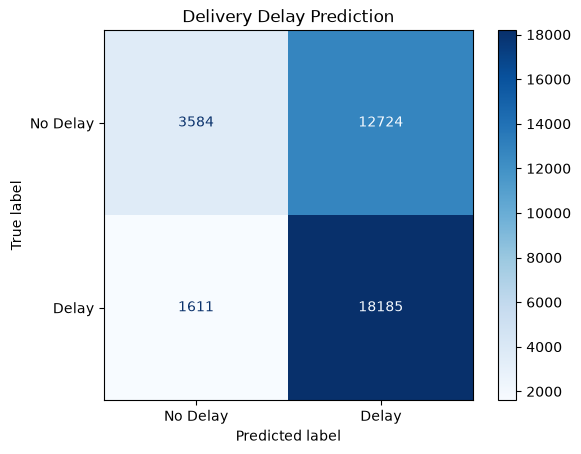

In [89]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Delay", "Delay"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Delivery Delay Prediction")
plt.show()

In [90]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

# Use the existing test probabilities
y_prob = model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in [0.35, 0.40, 0.45, 0.50, 0.60]:
    predictions = (y_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": round(accuracy_score(y_test, predictions), 4),
        "Precision": round(
            precision_score(y_test, predictions, zero_division=0), 4
        ),
        "Recall": round(
            recall_score(y_test, predictions, zero_division=0), 4
        ),
        "F1 Score": round(
            f1_score(y_test, predictions, zero_division=0), 4
        ),
        "False Positives": int(fp),
        "False Negatives": int(fn)
    })

show_output(pd.DataFrame(threshold_results))


,Threshold,Accuracy,Precision,Recall,F1 Score,False Positives,False Negatives
0,0.35,0.6030,0.5883,0.9186,0.7173,12724,1611
1,0.40,0.6791,0.7221,0.6741,0.6973,5135,6452
2,0.45,0.7009,0.8143,0.5888,0.6834,2659,8140
3,0.50,0.7008,0.8483,0.5532,0.6697,1958,8844
4,0.60,0.6990,0.8527,0.5452,0.6651,1864,9003


In [91]:
# Check the current prediction threshold and model settings

print("Model type:", type(model))
print("Classifier:", model.named_steps["classifier"])
print("Threshold used in evaluation: 0.40")

Model type: <class 'sklearn.pipeline.Pipeline'>
Classifier: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)
Threshold used in evaluation: 0.40


In [92]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.6029525814314204
              precision    recall  f1-score   support

           0       0.69      0.22      0.33     16308
           1       0.59      0.92      0.72     19796

    accuracy                           0.60     36104
   macro avg       0.64      0.57      0.53     36104
weighted avg       0.63      0.60      0.54     36104



In [93]:
from sklearn.metrics import accuracy_score, classification_report
import numpy as np

y_prob = model.predict_proba(X_test)[:, 1]

threshold = 0.40
y_pred_40 = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_test, y_pred_40), 4))
print(classification_report(
    y_test, y_pred_40, zero_division=0
))

Threshold: 0.4
Accuracy: 0.6791
              precision    recall  f1-score   support

           0       0.63      0.69      0.66     16308
           1       0.72      0.67      0.70     19796

    accuracy                           0.68     36104
   macro avg       0.68      0.68      0.68     36104
weighted avg       0.68      0.68      0.68     36104



In [95]:
threshold = 0.45
y_pred_45 = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_test, y_pred_45), 4))
print(classification_report(
    y_test, y_pred_45, zero_division=0
))

Threshold: 0.45
Accuracy: 0.7009
              precision    recall  f1-score   support

           0       0.63      0.84      0.72     16308
           1       0.81      0.59      0.68     19796

    accuracy                           0.70     36104
   macro avg       0.72      0.71      0.70     36104
weighted avg       0.73      0.70      0.70     36104



In [96]:
threshold = 0.50
y_pred_45 = (y_prob >= threshold).astype(int)

print("Threshold:", threshold)
print("Accuracy:", round(accuracy_score(y_test, y_pred_45), 4))
print(classification_report(
    y_test, y_pred_45, zero_division=0
))

Threshold: 0.5
Accuracy: 0.7008
              precision    recall  f1-score   support

           0       0.62      0.88      0.73     16308
           1       0.85      0.55      0.67     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.72      0.70     36104
weighted avg       0.74      0.70      0.70     36104

